# DERCONNECT real-data exploration and integration preparation
Checkpoint: November 6, 2026. This notebook is an offline inspection workflow, not dashboard ingestion or fault diagnosis. Clear all outputs before committing. Samples are file prefixes, not random or complete observations.

## A — Dataset overview and provenance
Instructor Haojian Jin supplied January–May 2026 data for five meters (coverage is reported, **not yet verified**). Authorized classifications: E2451 Instructional; E3020 Mixed; E3510/E7080/E7085 Office. Do not infer named buildings or electrical relationships. The approximately 3 GB local archive is not bundled or uploaded. Raw measurements and local reports must stay outside version control.

The dashboard fixtures are simulated hourly kW with simulated weather, occupancy, forecasts, labels and detections; these do not describe this archive. The browser CSV view accepts a separate provisional `timestamp,meter_id,kw` format, not arbitrary raw registers.

Install `requirements-derconnect.txt`, set `DERCONNECT_DATA_PATH` locally, then run all cells. The utility inventories ZIP metadata and streams a bounded prefix of each CSV/TSV. Parquet is optional and only read when the complete member fits the byte budget; larger Parquet needs local metadata/row-group work. Unsupported formats appear as explicit errors. No archive extraction occurs.

In [8]:
import os

os.environ["DERCONNECT_DATA_PATH"] = os.path.expanduser(
    "~/Desktop/Haojian_Data.zip"
)

from pathlib import Path
import os, sys, zipfile
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'tools/inspect_derconnect.py').exists()), None)
if ROOT is None:
    raise RuntimeError('Launch Jupyter from the repository root or notebooks directory.')
sys.path.insert(0, str(ROOT / 'tools'))
from inspect_derconnect import inspect, read_member, METERS, UNITS
path_text = os.environ.get('DERCONNECT_DATA_PATH', '')
DATA_PATH = Path(path_text).expanduser() if path_text else None
report = None
if DATA_PATH is None or not DATA_PATH.is_file():
    print('Real data unavailable. Set DERCONNECT_DATA_PATH to your local ZIP and restart/run all. No findings or plots generated.')
else:
    report = inspect(DATA_PATH, rows=2000, max_bytes=8*1024*1024)
    display(pd.Series({k:v for k,v in report.items() if k not in ['files', 'schema_variants']}))
    display(pd.DataFrame([{k:v for k,v in f.items() if k in ['name','meter','months_in_name','format','compressed_bytes','uncompressed_bytes','inspection_error']} for f in report['files']]))

archive_bytes                                                      3513736717
scope                       Per-file prefix samples; no full-data claims o...
file_count                                                                 25
compressed_bytes                                                   3513729939
uncompressed_bytes                                                11945502711
meters_observed_in_paths                  [E2451, E3020, E3510, E7080, E7085]
missing_expected_meters                                                    []
month_note                  Name tokens only; verify timestamp coverage be...
dtype: object

,name,meter,months_in_name,compressed_bytes,uncompressed_bytes,format
0,Haojian_Data/E2451/E2451_2026-01.csv,E2451,[2026-01],143619676,480616583,.csv
1,Haojian_Data/E2451/E2451_2026-02.csv,E2451,[2026-02],129225294,432020055,.csv
2,Haojian_Data/E2451/E2451_2026-03.csv,E2451,[2026-03],143337889,481096826,.csv
3,Haojian_Data/E2451/E2451_2026-04.csv,E2451,[2026-04],139456279,466089014,.csv
4,Haojian_Data/E2451/E2451_2026-05.csv,E2451,[2026-05],144269897,482143079,.csv
5,Haojian_Data/E3020/E3020_2026-04.csv,E3020,[2026-04],135525493,478406882,.csv
6,Haojian_Data/E3020/E3020_2026-03.csv,E3020,[2026-03],139615836,492953066,.csv
7,Haojian_Data/E3020/E3020_2026-05.csv,E3020,[2026-05],140057378,494228518,.csv
8,Haojian_Data/E3020/E3020_2026-02.csv,E3020,[2026-02],126936207,446297374,.csv
9,Haojian_Data/E3020/E3020_2026-01.csv,E3020,[2026-01],140532601,494013272,.csv


## B — Schema inspection
Compare every file's bounded prefix, including failures. String ingestion preserves missing encodings; inferred numeric counts are separate from storage dtype. Expected units below come from the instructor mapping and are **not verified file metadata**. Long-form `register,value,unit` files require an adapter; column-name matching alone cannot establish their availability.

In [9]:
if report:
    display(pd.DataFrame([{'file':f['name'], 'columns':f.get('columns'), 'storage_dtypes':f.get('dtypes'), 'timestamp_candidates':f.get('timestamp_candidates'), 'error':f.get('inspection_error')} for f in report['files']]))
    print('Schema variants:', report['schema_variants'])

,file,columns,storage_dtypes,timestamp_candidates,error
0,Haojian_Data/E2451/E2451_2026-01.csv,"[_time, DeviceID, Active_Energy_in_Quadrant_I,...","{'_time': 'str', 'DeviceID': 'str', 'Active_En...",[_time],None
1,Haojian_Data/E2451/E2451_2026-02.csv,"[_time, DeviceID, Active_Energy_in_Quadrant_I,...","{'_time': 'str', 'DeviceID': 'str', 'Active_En...",[_time],None
2,Haojian_Data/E2451/E2451_2026-03.csv,"[_time, DeviceID, Active_Energy_in_Quadrant_I,...","{'_time': 'str', 'DeviceID': 'str', 'Active_En...",[_time],None
3,Haojian_Data/E2451/E2451_2026-04.csv,"[_time, DeviceID, Active_Energy_in_Quadrant_I,...","{'_time': 'str', 'DeviceID': 'str', 'Active_En...",[_time],None
4,Haojian_Data/E2451/E2451_2026-05.csv,"[_time, DeviceID, Active_Energy_in_Quadrant_I,...","{'_time': 'str', 'DeviceID': 'str', 'Active_En...",[_time],None
5,Haojian_Data/E3020/E3020_2026-04.csv,"[_time, DeviceID, Active_Energy_in_Quadrant_I,...","{'_time': 'str', 'DeviceID': 'str', 'Active_En...",[_time],None
6,Haojian_Data/E3020/E3020_2026-03.csv,"[_time, DeviceID, Active_Energy_in_Quadrant_I,...","{'_time': 'str', 'DeviceID': 'str', 'Active_En...",[_time],None
7,Haojian_Data/E3020/E3020_2026-05.csv,"[_time, DeviceID, Active_Energy_in_Quadrant_I,...","{'_time': 'str', 'DeviceID': 'str', 'Active_En...",[_time],None
8,Haojian_Data/E3020/E3020_2026-02.csv,"[_time, DeviceID, Active_Energy_in_Quadrant_I,...","{'_time': 'str', 'DeviceID': 'str', 'Active_En...",[_time],None
9,Haojian_Data/E3020/E3020_2026-01.csv,"[_time, DeviceID, Active_Energy_in_Quadrant_I,...","{'_time': 'str', 'DeviceID': 'str', 'Active_En...",[_time],None


Schema variants: [['_time', 'DeviceID', 'Active_Energy_in_Quadrant_I', 'Active_Energy_in_Quadrant_II', 'Active_Energy_in_Quadrant_III', 'Active_Energy_in_Quadrant_IV', 'Active_Power_A', 'Active_Power_B', 'Active_Power_C', 'Apparent_Power_A', 'Apparent_Power_B', 'Apparent_Power_C', 'Current_A', 'Current_B', 'Current_C', 'Current_Unbalance_Worst', 'Frequency', 'Power_Factor_A', 'Power_Factor_B', 'Power_Factor_C', 'Reactive_Power_A', 'Reactive_Power_B', 'Reactive_Power_C', 'THD_Current_A', 'THD_Current_B', 'THD_Current_C', 'THD_Current_N', 'THD_Voltage_A-N', 'THD_Voltage_B-N', 'THD_Voltage_C-N', 'Voltage_A-B', 'Voltage_A-N', 'Voltage_B-C', 'Voltage_B-N', 'Voltage_C-A', 'Voltage_C-N', 'Voltage_Unbalance_L-N_Worst']]


## C — Timestamp and sampling analysis
ISO timestamps only: choose `--timestamp` for ambiguous candidates; epoch, split date/time and local formats require explicit parsing rules. Cadence is the modal positive interval in file order, separately per file/meter. Duplicates and backwards steps are retained as evidence. Gaps use sorted unique times and a 1.5× modal interval threshold; off-cadence uses 1% tolerance. These are diagnostics, not a verified schedule. Cross-file duplicates and full-month coverage remain untested.

Naive timestamps stay naive: do not localize without source confirmation. Campus `America/Los_Angeles` crosses DST on March 8, 2026; nonexistent local times require a documented rule. Explicit offsets identify instants but do not prove a timezone. No real-data use of the dashboard's wall-time-as-UTC shortcut.

In [10]:
if report:
    display(pd.DataFrame([{'file':f['name'], 'meter':f['meter'], **f.get('time', {}), 'note':f.get('time_warning')} for f in report['files']]))
    expected = {f'2026-{m:02}' for m in range(1,6)}
    for meter in METERS:
        observed = {token.replace('_','-') if len(token)==7 else token[:4]+'-'+token[4:] for f in report['files'] if f['meter']==meter for token in f['months_in_name']}
        print(meter, 'missing filename tokens:', sorted(expected-observed), 'unexpected:', sorted(observed-expected))
    print('Filename-month checks are provisional; use timestamps to verify actual coverage.')

,file,meter,parsed,invalid,naive,offset_aware,start,end,duplicate_timestamps,backwards,interval_counts_seconds,modal_interval_seconds,large_gaps,off_cadence,max_gap_seconds,warning,note
0,Haojian_Data/E2451/E2451_2026-01.csv,E2451,2000,0,0,2000,2026-01-01T08:00:00.173662+00:00,2026-01-01T09:06:38.294606+00:00,0,0,"[(2.000324, 5), (1.999874, 5), (1.999929, 5), ...",2.000324,0,0,2.004022,Offsets do not identify a campus timezone,None
1,Haojian_Data/E2451/E2451_2026-02.csv,E2451,2000,0,0,2000,2026-02-01T08:00:01.983799+00:00,2026-02-01T09:06:40.106640+00:00,0,0,"[(2.000529, 7), (2.000067, 6), (1.999802, 5), ...",2.000529,0,2,2.024472,Offsets do not identify a campus timezone,None
2,Haojian_Data/E2451/E2451_2026-03.csv,E2451,2000,0,0,2000,2026-03-01T08:00:01.025074+00:00,2026-03-01T09:06:39.164847+00:00,0,0,"[(1.999973, 5), (2.000434, 4), (2.000538, 4), ...",1.999973,0,322,2.045036,Offsets do not identify a campus timezone,None
3,Haojian_Data/E2451/E2451_2026-04.csv,E2451,2000,0,0,2000,2026-04-01T07:00:01.688498+00:00,2026-04-01T08:06:39.814754+00:00,0,0,"[(1.999855, 6), (2.000135, 6), (1.999827, 5), ...",1.999855,0,109,2.029708,Offsets do not identify a campus timezone,None
4,Haojian_Data/E2451/E2451_2026-05.csv,E2451,2000,0,0,2000,2026-05-01T07:00:00.322278+00:00,2026-05-01T08:06:38.481990+00:00,0,0,"[(2.00028, 6), (1.999836, 5), (2.000113, 5), (...",2.000280,0,16,2.023779,Offsets do not identify a campus timezone,None
5,Haojian_Data/E3020/E3020_2026-04.csv,E3020,2000,0,0,2000,2026-04-01T07:00:01.769625+00:00,2026-04-01T08:06:39.897169+00:00,0,0,"[(2.002963, 2), (1.978699, 2), (2.002466, 2), ...",2.002963,0,590,2.228446,Offsets do not identify a campus timezone,None
6,Haojian_Data/E3020/E3020_2026-03.csv,E3020,2000,0,0,2000,2026-03-01T08:00:01.106570+00:00,2026-03-01T09:06:39.265906+00:00,0,0,"[(2.000077, 3), (2.001187, 2), (2.000814, 2), ...",2.000077,0,694,2.177354,Offsets do not identify a campus timezone,None
7,Haojian_Data/E3020/E3020_2026-05.csv,E3020,2000,0,0,2000,2026-05-01T07:00:00.403158+00:00,2026-05-01T08:06:38.564396+00:00,0,0,"[(2.000229, 3), (2.002951, 3), (2.000533, 3), ...",2.000229,0,218,2.103268,Offsets do not identify a campus timezone,None
8,Haojian_Data/E3020/E3020_2026-02.csv,E3020,2000,0,0,2000,2026-02-01T08:00:00.064319+00:00,2026-02-01T09:06:38.214468+00:00,0,0,"[(2.00288, 3), (2.003294, 3), (1.999792, 3), (...",2.002880,0,430,2.072794,Offsets do not identify a campus timezone,None
9,Haojian_Data/E3020/E3020_2026-01.csv,E3020,2000,0,0,2000,2026-01-01T08:00:00.257808+00:00,2026-01-01T09:06:38.398942+00:00,0,0,"[(2.000298, 4), (1.998832, 3), (2.000385, 3), ...",2.000298,0,490,2.039254,Offsets do not identify a campus timezone,None


E2451 missing filename tokens: [] unexpected: []
E3020 missing filename tokens: [] unexpected: []
E3510 missing filename tokens: [] unexpected: []
E7080 missing filename tokens: [] unexpected: []
E7085 missing filename tokens: [] unexpected: []
Filename-month checks are provisional; use timestamps to verify actual coverage.


## D — Measurement availability and quality
The matrix means “column observed in a sampled schema”, not “valid data for the full period”. Unknown names and metadata remain in the schema table. Ranges, missing encodings and nonnumeric counts are bounded diagnostics; units require source confirmation. Do not treat counter energy as power.

In [11]:
if report:
    availability = pd.DataFrame({m:{r:any(r in f.get('columns',[]) for f in report['files'] if f['meter']==m) for r in UNITS} for m in METERS})
    display(availability)
    quality = pd.DataFrame([{'meter':f['meter'], 'file':f['name'], 'column':c, 'expected_unit':UNITS.get(c), **q} for f in report['files'] for c,q in f.get('quality',{}).items()])
    display(quality)

,E2451,E3020,E3510,E7080,E7085
Active_Energy_in_Quadrant_I,True,True,True,True,True
Active_Energy_in_Quadrant_II,True,True,True,True,True
Active_Energy_in_Quadrant_III,True,True,True,True,True
Active_Energy_in_Quadrant_IV,True,True,True,True,True
Active_Power_A,True,True,True,True,True
Active_Power_B,True,True,True,True,True
Active_Power_C,True,True,True,True,True
Apparent_Power_A,True,True,True,True,True
Apparent_Power_B,True,True,True,True,True
Apparent_Power_C,True,True,True,True,True


,meter,file,column,expected_unit,missing,non_numeric,nonfinite,numeric_count,min,max,negative,adjacent_equal,decreases
0,E2451,Haojian_Data/E2451/E2451_2026-01.csv,_time,NaN,0,2000,0,0,NaN,NaN,0,0,0
1,E2451,Haojian_Data/E2451/E2451_2026-01.csv,DeviceID,NaN,0,2000,0,0,NaN,NaN,0,0,0
2,E2451,Haojian_Data/E2451/E2451_2026-01.csv,Active_Energy_in_Quadrant_I,kWh,0,0,0,2000,3.073328e+06,3.073369e+06,0,1833,0
3,E2451,Haojian_Data/E2451/E2451_2026-01.csv,Active_Energy_in_Quadrant_II,kWh,0,0,0,2000,3.000000e-05,3.000000e-05,0,1999,0
4,E2451,Haojian_Data/E2451/E2451_2026-01.csv,Active_Energy_in_Quadrant_III,kWh,0,0,0,2000,0.000000e+00,0.000000e+00,0,1999,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
920,E7085,Haojian_Data/E7085/E7085_2026-05.csv,Voltage_B-C,V,0,0,0,2000,4.850290e+02,4.888888e+02,0,156,931
921,E7085,Haojian_Data/E7085/E7085_2026-05.csv,Voltage_B-N,V,0,0,0,2000,2.797855e+02,2.820201e+02,0,157,929
922,E7085,Haojian_Data/E7085/E7085_2026-05.csv,Voltage_C-A,V,0,0,0,2000,4.843855e+02,4.883060e+02,0,157,926
923,E7085,Haojian_Data/E7085/E7085_2026-05.csv,Voltage_C-N,V,0,0,0,2000,2.799835e+02,2.822246e+02,0,156,932


## E — Exploratory visualizations
Choose a successfully inspected file and an exact register. No automatic phase sum is calculated: phase compatibility, simultaneity, net/import conventions and register semantics need confirmation. Hour/day profiles below are retrospective sample means, not energy or complete daily totals. UTC hours for offset-aware timestamps are not campus occupancy hours. Short file prefixes rarely support weekly conclusions.

Run the selected-file cell for each meter and supported voltage/frequency/current/phase register. Compare building classes only with matched windows, cadences and confirmed units; no class comparison is valid from unmatched prefixes. Change `SELECTED_NAME` to select a file explicitly.

Bounded prefix: Haojian_Data/E2451/E2451_2026-01.csv limited: True


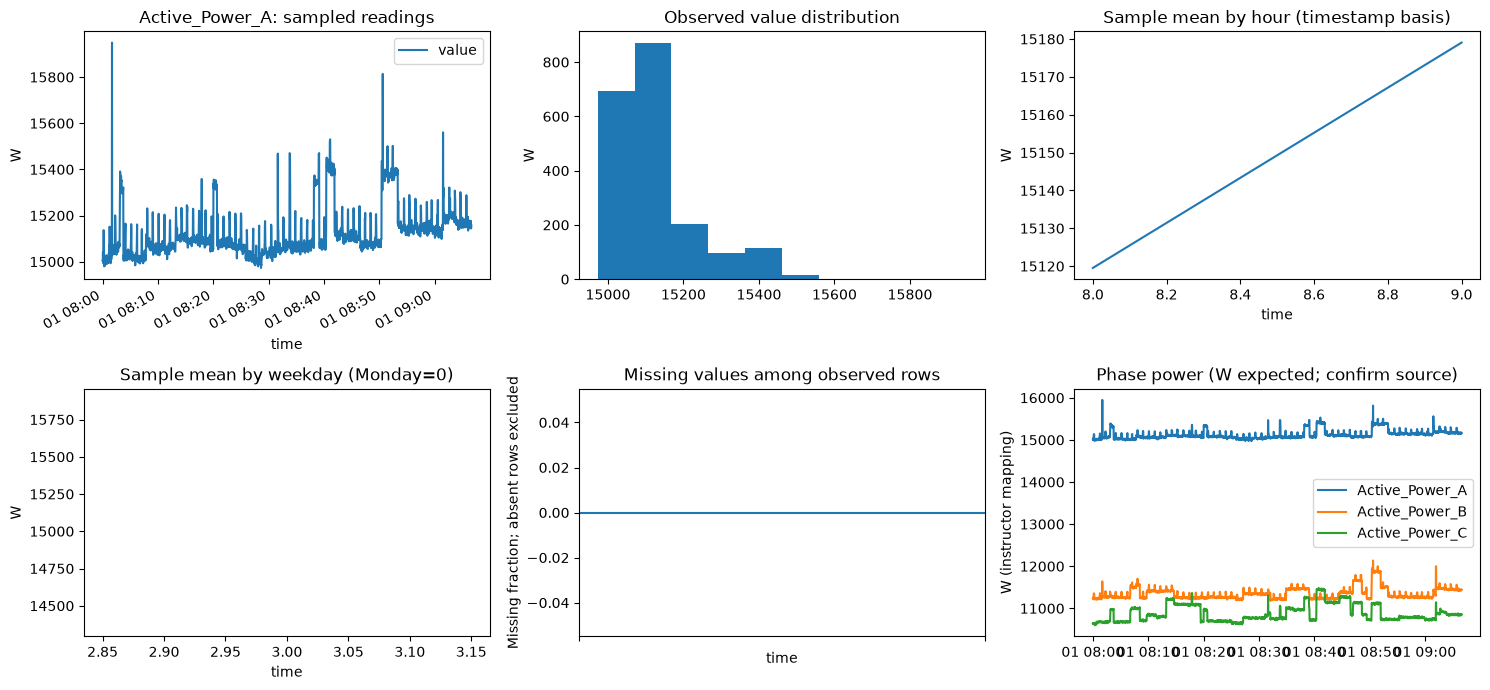

In [12]:
SELECTED_NAME = None
REGISTER = 'Active_Power_A'
frame = None
if report:
    candidates = [f for f in report['files'] if 'time_column' in f and REGISTER in f.get('columns', [])]
    selected = next((f for f in candidates if f['name']==SELECTED_NAME), None) if SELECTED_NAME else next(iter(candidates), None)
    if selected:
        with zipfile.ZipFile(DATA_PATH) as archive:
            frame, limited = read_member(archive, archive.getinfo(selected['name']), rows=2000)
        print('Bounded prefix:', selected['name'], 'limited:', limited)
    else:
        print('No supported timestamp/register pair. Inspect schema and select a register/parser; no plot generated.')
if frame is not None:
    if selected.get('time', {}).get('naive') and selected.get('time', {}).get('offset_aware'):
        print('Mixed time bases: resolve before plotting.')
    else:
        t = pd.to_datetime(frame[selected['time_column']], errors='coerce', utc=bool(selected.get('time',{}).get('offset_aware')))
        v = pd.to_numeric(frame[REGISTER], errors='coerce').replace([float('inf'), -float('inf')], float('nan'))
        sample = pd.DataFrame({'time':t, 'value':v}).dropna(subset=['time']).sort_values('time')
        unit = UNITS.get(REGISTER, 'unverified unit')
        fig, axes = plt.subplots(2, 3, figsize=(15,7))
        sample.plot(x='time', y='value', ax=axes[0,0], title=f'{REGISTER}: sampled readings')
        sample['value'].plot.hist(ax=axes[0,1], title='Observed value distribution')
        sample.groupby(sample.time.dt.hour)['value'].mean().plot(ax=axes[0,2], title='Sample mean by hour (timestamp basis)')
        sample.groupby(sample.time.dt.dayofweek)['value'].mean().plot(ax=axes[1,0], title='Sample mean by weekday (Monday=0)')
        sample.set_index('time')['value'].isna().resample('h').mean().plot(ax=axes[1,1], title='Missing values among observed rows')
        phases = [c for c in ['Active_Power_A','Active_Power_B','Active_Power_C'] if c in frame]
        for c in phases:
            axes[1,2].plot(t, pd.to_numeric(frame[c], errors='coerce'), label=c)
        axes[1,2].set_title('Phase power (W expected; confirm source)')
        if phases: axes[1,2].legend()
        for ax in axes.flat: ax.set_ylabel(unit)
        axes[1,1].set_ylabel('Missing fraction; absent rows excluded')
        axes[1,2].set_ylabel('W (instructor mapping)')
        plt.tight_layout()
        plt.show()

## Preliminary DERCONNECT Dataset Findings

**Dataset source:** Initial DERCONNECT meter dataset shared by Haojian Jin, covering January–May 2026.

### Dataset structure

- The archive contains 25 monthly CSV files organized across five meter/device IDs: E2451, E3020, E3510, E7080, and E7085.
- The archive is approximately 3.5 GB compressed and 11.9 GB uncompressed.
- All five devices have a file for each month from January through May 2026.
- The inspected files share a consistent schema covering active energy, active and apparent power, voltage, current, frequency, power factor, reactive power, harmonic distortion, and phase unbalance.

### Preliminary data quality and sampling

- The sampled timestamps use the `_time` column and include UTC offsets.
- Observations appear to occur approximately every two seconds.
- The initial inspection examined 2,000 rows per monthly file.
- No invalid or duplicate timestamps were identified within those inspected samples.
- The selected measurement registers showed generally complete values in the sampled rows.
- Some registers were constant within the sampled intervals, requiring further investigation.

### Initial visualization

- Real active-power measurements were successfully visualized.
- Short-term load fluctuations and differences between electrical phases were visible.
- The current sampling window spans approximately 67 minutes per file, limiting conclusions about daily and weekly patterns.
- Longer-period aggregation is needed before comparing typical behavior across building types or identifying unusual consumption patterns.

### Implications for dashboard integration

- Raw two-second measurements are unnecessarily detailed for many campus-level dashboard visualizations.
- A reproducible aggregation layer will likely be needed for interactive building-level trends.
- Original-resolution measurements may remain useful for inspecting short-duration events.
- Building identities should remain tied to their provided device IDs until physical building names are verified.
- Real measurements should remain distinguishable from the existing synthetic demonstration dataset.

### Next steps

1. Perform memory-efficient full-period quality and coverage analysis.
2. Evaluate five-minute, fifteen-minute, and hourly aggregation.
3. Verify active-power phase aggregation and timestamp conventions.
4. Coordinate with the anomaly detection team on model input requirements.
5. Define a common data interface for real measurements, forecasts, anomaly scores, and detected events.

**Limitations:** These are preliminary findings based on bounded file-prefix samples, not a comprehensive analysis of the full five-month dataset. No operational electrical faults have been confirmed.

## F — Full Dataset Quality

This section reads every recognized CSV **through EOF**, in chunks, rather than extending the 2,000-row prefixes. It retains compact timestamp arrays for one device at a time, cadence-slot masks, register counters, 5/15/60-minute summaries and a bounded raw detail window in memory. The ZIP is never extracted; no report or aggregated dataset is exported. Expect a multi-minute scan of approximately 11.95 GB decompressed data; progress prints per file and every ten chunks. Rerunning the scan repeats the I/O.

**Explicit assumptions and denominators**
- `FG_MONTHS` and `FG_DEVICES` default to all 25 expected device/month combinations. File counts and unrecognized CSVs are reported; missing files produce zero coverage, not a successful complete-data claim.
- Expected cadence is provisionally **2 seconds**. Coverage is occupied, half-open two-second slots / expected slots in the **entire calendar month**, not rows / rows observed. Nearby jittered readings in the same slot count once. Sampling summaries use sorted unique intervals (median, 1st and 99th percentiles); off-cadence counts use a 10% tolerance around the configured cadence. Use these diagnostics to review the schedule; it is not inferred as an exact hardware guarantee.
- `FG_CALENDAR_TZ = 'America/Los_Angeles'` explicitly assumes campus-local filename months. Verify this with the data owner. Offset-aware source timestamps are converted to UTC; naive, missing and invalid timestamps are reported and excluded. Local month/day boundaries account for DST (March has a 23-hour day). Change this configuration if the month convention differs.
- Source file/device/month labels are validated against `_time` and `DeviceID`. Out-of-month rows and mismatched IDs are reported and excluded from coverage/aggregation, rather than silently reassigned. Exact timestamp duplicates are checked across chunks and files per device. Backwards steps describe file order; intervals describe sorted unique instants.
- Register missing/invalid counts cover **all source rows**, including rows with unusable time. Missing means blank/known missing token or absent register; invalid means nonnumeric/nonfinite. The percentage denominator is source rows × expected mapped registers. Timestamp/ID failures have separate counts. No zeros are substituted.
- Clock jitter can create isolated empty grid slots without a long interval between observations. Separate recording-gap diagnostics count intervals exceeding 1.5 × the configured cadence; cross-month intervals are assigned to the month of the later reading. Neither check establishes an outage.
- Longest missing-slot runs include leading/trailing month gaps. Count all runs, retaining only the longest `FG_MAX_GAPS_PER_MONTH` per device/month for bounded plotting. A gap is a recording issue to investigate, not proof of an outage. Repeated values and negative power also need source context.

The numerical helper is `tools/derconnect_full_quality.py`; it reuses the existing `METERS`, `UNITS` and missing-token mapping. Sections F and G do not run detectors, create baselines, or analyze building consumption patterns.

In [13]:
from pathlib import Path
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from zoneinfo import ZoneInfo
from IPython.display import display

FG_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'tools/derconnect_full_quality.py').is_file()), None)
if FG_ROOT is None:
    raise RuntimeError('Launch Jupyter from the repository root or notebooks directory.')
if str(FG_ROOT / 'tools') not in sys.path:
    sys.path.insert(0, str(FG_ROOT / 'tools'))
from derconnect_full_quality import scan_archive, aggregation_summary, PHASES, MONTHS
from inspect_derconnect import METERS, UNITS

# Reuse the path configured in Section A. No new private path is embedded here.
FG_DATA_PATH = DATA_PATH if 'DATA_PATH' in globals() else Path(os.environ.get('DERCONNECT_DATA_PATH', '')).expanduser()
FG_DEVICES = list(METERS)
FG_MONTHS = list(MONTHS)
FG_CALENDAR_TZ = 'America/Los_Angeles'  # Explicit assumption; confirm source-month convention.
FG_CADENCE_SECONDS = 2
FG_CHUNK_ROWS = 25000
FG_MIN_VALID_COVERAGE = 0.80  # Display rule, not an anomaly threshold; inspect sensitivity.
FG_MAX_GAPS_PER_MONTH = 100
FG_DETAIL_DEVICE = 'E2451'
FG_DETAIL_START = None  # None = start of first available source month; or ISO timestamp with Z/offset.
FG_DETAIL_HOURS = 2
FG_MAX_DETAIL_ROWS = 10000

# Keep these False until source documentation confirms all three assumptions.
# Statistical similarity between phases cannot verify additive electrical semantics.
FG_PHASE_REVIEW = {
    'same_device_and_timestamp': False,
    'distinct_additive_phases': False,
    'compatible_signed_power_W': False,
    'source_reference': '',
}
FULL_RESULT = None

In [14]:
FULL_RESULT = None  # Do not retain stale results if a repeated scan fails.
if FG_DATA_PATH is None or not Path(FG_DATA_PATH).is_file():
    print('Full dataset unavailable. Configure DATA_PATH in Section A. No full-data findings generated.')
else:
    FULL_RESULT = scan_archive(
        FG_DATA_PATH, devices=FG_DEVICES, months=FG_MONTHS,
        calendar_tz=FG_CALENDAR_TZ, cadence_s=FG_CADENCE_SECONDS,
        chunksize=FG_CHUNK_ROWS, minimum_coverage=FG_MIN_VALID_COVERAGE,
        phase_review=FG_PHASE_REVIEW, detail_device=FG_DETAIL_DEVICE,
        detail_start=FG_DETAIL_START, detail_hours=FG_DETAIL_HOURS,
        max_detail_rows=FG_MAX_DETAIL_ROWS, max_gaps_per_month=FG_MAX_GAPS_PER_MONTH)
    meta = FULL_RESULT['metadata']
    print(f"EOF reached for {meta['complete_files']} CSVs; expected {meta['expected_files']} device/month files.")
    if meta['unrecognized_csvs']:
        print('Unrecognized/out-of-scope CSVs (not scanned):', meta['unrecognized_csvs'])
    print('All retained results are temporary Python objects; no datasets/reports were saved.')
    print('Total active power:', 'enabled by documented phase review' if FULL_RESULT['total_enabled'] else 'unavailable — phase-sum assumptions unverified')

[1/25] E2451 2026-01: reading complete CSV in 25,000-row chunks
  E2451 2026-01: 25,000 rows scanned
  E2451 2026-01: 275,000 rows scanned
  E2451 2026-01: 525,000 rows scanned
  E2451 2026-01: 775,000 rows scanned
  E2451 2026-01: 1,025,000 rows scanned
  E2451 2026-01: 1,275,000 rows scanned
[1/25] E2451 2026-01: EOF reached (1,338,543 rows)
[2/25] E2451 2026-02: reading complete CSV in 25,000-row chunks
  E2451 2026-02: 25,000 rows scanned
  E2451 2026-02: 275,000 rows scanned
  E2451 2026-02: 525,000 rows scanned
  E2451 2026-02: 775,000 rows scanned
  E2451 2026-02: 1,025,000 rows scanned
[2/25] E2451 2026-02: EOF reached (1,202,349 rows)
[3/25] E2451 2026-03: reading complete CSV in 25,000-row chunks
  E2451 2026-03: 25,000 rows scanned
  E2451 2026-03: 275,000 rows scanned
  E2451 2026-03: 525,000 rows scanned
  E2451 2026-03: 775,000 rows scanned
  E2451 2026-03: 1,025,000 rows scanned
  E2451 2026-03: 1,275,000 rows scanned
[3/25] E2451 2026-03: EOF reached (1,336,696 rows)
[4

In [15]:
if FULL_RESULT is not None:
    fq = FULL_RESULT['summary']
    display(fq[['device', 'month', 'files', 'rows', 'expected_slots', 'observed_slots',
                'coverage_pct', 'missing_slots', 'missing_timestamps', 'invalid_timestamps',
                'naive_timestamps', 'duplicate_rows', 'backwards_steps', 'device_id_mismatch',
                'outside_source_month', 'interval_median_s', 'interval_p01_s', 'interval_p99_s',
                'off_cadence_intervals', 'recording_gap_count', 'max_observed_interval_s', 'gap_count', 'max_gap_s',
                'missing_measurement_pct', 'invalid_measurement_pct', 'potential_issues']])
    fm = FULL_RESULT['measurements']
    display(fm[['device', 'month', 'register', 'mapped_unit', 'rows', 'finite', 'missing', 'invalid',
                'absent_column_rows', 'missing_pct', 'invalid_pct', 'min', 'max', 'negative', 'equal_adjacent']])
    print('Potential issues needing review (these checks do not diagnose electrical faults):')
    display(fq.loc[fq.potential_issues.ne('No issues under configured checks'),
                   ['device', 'month', 'potential_issues']])
    repeated = fm.loc[(fm.finite > 1) & (fm['min'] == fm['max']),
                     ['device', 'month', 'register', 'finite', 'equal_adjacent']]
    print(f'{len(repeated)} register/month entries are constant among finite values; counters or unused channels may legitimately be constant.')
    display(repeated)

,device,month,files,rows,expected_slots,observed_slots,coverage_pct,missing_slots,missing_timestamps,invalid_timestamps,...,interval_p01_s,interval_p99_s,off_cadence_intervals,recording_gap_count,max_observed_interval_s,gap_count,max_gap_s,missing_measurement_pct,invalid_measurement_pct,potential_issues
0,E2451,2026-01,1,1338543,1339200,1338320,99.934289,880,0,0,...,1.997336,2.002850,105,26,1176.546156,294,1174.0,0.0,0.0,"missing_slots, recording_gap_count"
1,E2451,2026-02,1,1202349,1209600,1201950,99.367560,7650,0,0,...,1.979435,2.020699,103,16,13204.457291,453,13202.0,0.0,0.0,"missing_slots, recording_gap_count"
2,E2451,2026-03,1,1336696,1337400,1335511,99.858756,1889,0,0,...,1.976966,2.023224,117,19,1230.805125,1250,1230.0,0.0,0.0,"missing_slots, recording_gap_count"
3,E2451,2026-04,1,1294677,1296000,1294150,99.857253,1850,0,0,...,1.978059,2.022137,129,22,1271.704112,594,1270.0,0.0,0.0,"missing_slots, recording_gap_count"
4,E2451,2026-05,1,1338436,1339200,1338202,99.925478,998,0,0,...,1.997209,2.002987,121,31,1274.751078,306,1272.0,0.0,0.0,"missing_slots, recording_gap_count"
5,E3020,2026-01,1,1338566,1339200,1335189,99.700493,4011,0,0,...,1.961290,2.044506,525,2,1176.505971,3425,1174.0,0.0,0.0,"missing_slots, recording_gap_count"
6,E3020,2026-02,1,1208965,1209600,1205920,99.695767,3680,0,0,...,1.958022,2.045428,519,1,1198.362584,3083,1196.0,0.0,0.0,"missing_slots, recording_gap_count"
7,E3020,2026-03,1,1336712,1337400,1333328,99.695529,4072,0,0,...,1.960802,2.042411,616,4,1230.700366,3433,1230.0,0.0,0.0,"missing_slots, recording_gap_count"
8,E3020,2026-04,1,1294696,1296000,1291217,99.630941,4783,0,0,...,1.963302,2.039705,660,6,1271.599867,3527,1270.0,0.0,0.0,"missing_slots, recording_gap_count"
9,E3020,2026-05,1,1338464,1339200,1335843,99.749328,3357,0,0,...,1.969239,2.031454,370,3,1274.668561,2665,1272.0,0.0,0.0,"missing_slots, recording_gap_count"


,device,month,register,mapped_unit,rows,finite,missing,invalid,absent_column_rows,missing_pct,invalid_pct,min,max,negative,equal_adjacent
0,E2451,2026-01,Active_Energy_in_Quadrant_I,kWh,1338543,1338543,0,0,0,0.0,0.0,3.073328e+06,3.125208e+06,0,1131042
1,E2451,2026-01,Active_Energy_in_Quadrant_II,kWh,1338543,1338543,0,0,0,0.0,0.0,3.000000e-05,3.000000e-05,0,1338542
2,E2451,2026-01,Active_Energy_in_Quadrant_III,kWh,1338543,1338543,0,0,0,0.0,0.0,0.000000e+00,0.000000e+00,0,1338542
3,E2451,2026-01,Active_Energy_in_Quadrant_IV,kWh,1338543,1338543,0,0,0,0.0,0.0,0.000000e+00,0.000000e+00,0,1338542
4,E2451,2026-01,Active_Power_A,W,1338543,1338543,0,0,0,0.0,0.0,1.404938e+04,6.420300e+04,0,76373
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
870,E7085,2026-05,Voltage_C-A,V,1338453,1338453,0,0,0,0.0,0.0,4.774439e+02,4.971628e+02,0,100632
871,E7085,2026-05,Voltage_C-N,V,1338453,1338453,0,0,0,0.0,0.0,2.765525e+02,2.872131e+02,0,100695
872,E7085,2026-05,Frequency,Hz,1338453,1338453,0,0,0,0.0,0.0,5.992310e+01,6.007827e+01,0,102396
873,E7085,2026-05,Current_Unbalance_Worst,%,1338453,1338453,0,0,0,0.0,0.0,1.940000e-03,3.246500e-01,0,105057


Potential issues needing review (these checks do not diagnose electrical faults):


,device,month,potential_issues
0,E2451,2026-01,"missing_slots, recording_gap_count"
1,E2451,2026-02,"missing_slots, recording_gap_count"
2,E2451,2026-03,"missing_slots, recording_gap_count"
3,E2451,2026-04,"missing_slots, recording_gap_count"
4,E2451,2026-05,"missing_slots, recording_gap_count"
5,E3020,2026-01,"missing_slots, recording_gap_count"
6,E3020,2026-02,"missing_slots, recording_gap_count"
7,E3020,2026-03,"missing_slots, recording_gap_count"
8,E3020,2026-04,"missing_slots, recording_gap_count"
9,E3020,2026-05,"missing_slots, recording_gap_count"


99 register/month entries are constant among finite values; counters or unused channels may legitimately be constant.


,device,month,register,finite,equal_adjacent
1,E2451,2026-01,Active_Energy_in_Quadrant_II,1338543,1338542
2,E2451,2026-01,Active_Energy_in_Quadrant_III,1338543,1338542
3,E2451,2026-01,Active_Energy_in_Quadrant_IV,1338543,1338542
22,E2451,2026-01,THD_Current_N,1338543,1338542
36,E2451,2026-02,Active_Energy_in_Quadrant_II,1202349,1202348
...,...,...,...,...,...
808,E7085,2026-04,Active_Energy_in_Quadrant_IV,1294685,1294684
827,E7085,2026-04,THD_Current_N,1294685,1294684
841,E7085,2026-05,Active_Energy_in_Quadrant_II,1338453,1338452
842,E7085,2026-05,Active_Energy_in_Quadrant_III,1338453,1338452


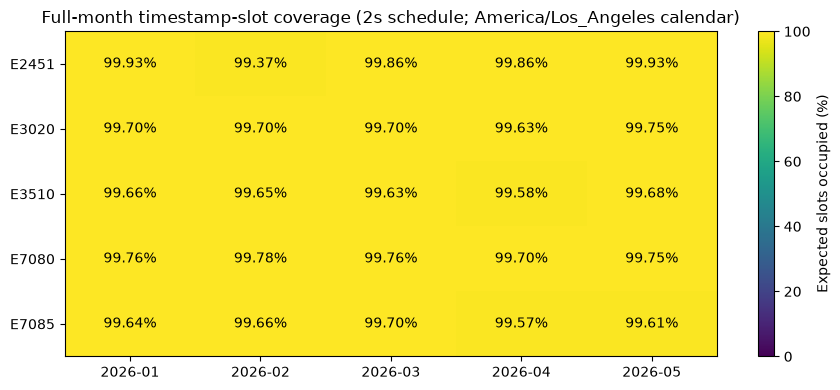

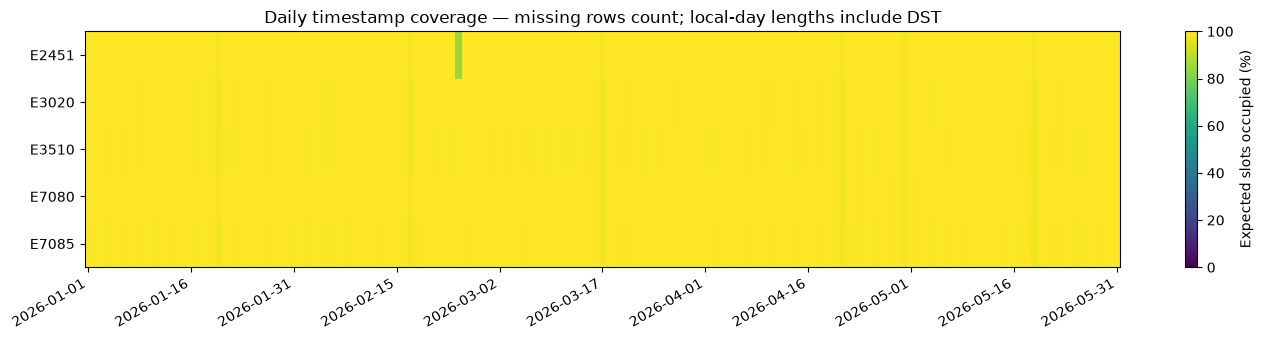

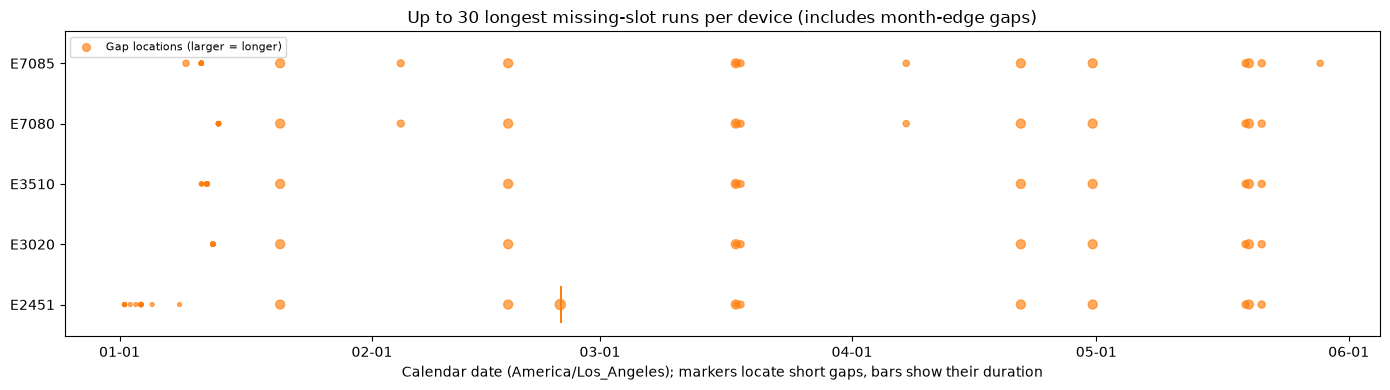

,device,month,start_utc,end_utc,missing_slots,duration_s
172,E2451,2026-02,2026-02-24 11:05:40+00:00,2026-02-24 14:45:42+00:00,6601,13202.0
1470,E3510,2026-05,2026-05-20 00:45:36+00:00,2026-05-20 01:06:50+00:00,637,1274.0
2494,E7085,2026-05,2026-05-20 00:45:36+00:00,2026-05-20 01:06:50+00:00,637,1274.0
450,E2451,2026-05,2026-05-20 00:45:36+00:00,2026-05-20 01:06:48+00:00,636,1272.0
984,E3020,2026-05,2026-05-20 00:45:36+00:00,2026-05-20 01:06:48+00:00,636,1272.0
1925,E7080,2026-05,2026-05-20 00:45:36+00:00,2026-05-20 01:06:48+00:00,636,1272.0
388,E2451,2026-04,2026-04-22 00:33:52+00:00,2026-04-22 00:55:02+00:00,635,1270.0
855,E3020,2026-04,2026-04-22 00:33:52+00:00,2026-04-22 00:55:02+00:00,635,1270.0
1349,E3510,2026-04,2026-04-22 00:33:52+00:00,2026-04-22 00:55:02+00:00,635,1270.0
1871,E7080,2026-04,2026-04-22 00:33:52+00:00,2026-04-22 00:55:02+00:00,635,1270.0


Elapsed recording gaps (>1.5 × configured cadence); unlike slot holes, these measure time between actual readings:


,device,month,start_utc,end_utc,interval_s,duration_s
39,E2451,2026-02,2026-02-24 11:05:40.404071+00:00,2026-02-24 14:45:42.861362+00:00,13204.457291,13202.457291
203,E7085,2026-05,2026-05-20 00:45:36.569289+00:00,2026-05-20 01:06:51.528037+00:00,1276.958748,1274.958748
157,E3510,2026-05,2026-05-20 00:45:36.548054+00:00,2026-05-20 01:06:51.505241+00:00,1276.957187,1274.957187
104,E2451,2026-05,2026-05-20 00:45:36.414080+00:00,2026-05-20 01:06:49.165158+00:00,1274.751078,1272.751078
128,E3020,2026-05,2026-05-20 00:45:36.497540+00:00,2026-05-20 01:06:49.166101+00:00,1274.668561,1272.668561
176,E7080,2026-05,2026-05-20 00:45:36.497630+00:00,2026-05-20 01:06:49.166165+00:00,1274.668535,1272.668535
77,E2451,2026-04,2026-04-22 00:33:52.408079+00:00,2026-04-22 00:55:02.112191+00:00,1271.704112,1269.704112
170,E7080,2026-04,2026-04-22 00:33:52.514538+00:00,2026-04-22 00:55:02.114453+00:00,1271.599915,1269.599915
122,E3020,2026-04,2026-04-22 00:33:52.514472+00:00,2026-04-22 00:55:02.114339+00:00,1271.599867,1269.599867
150,E3510,2026-04,2026-04-22 00:33:52.576406+00:00,2026-04-22 00:55:02.119615+00:00,1271.543209,1269.543209


In [16]:
if FULL_RESULT is not None:
    matrix = FULL_RESULT['summary'].pivot(index='device', columns='month', values='coverage_pct').reindex(index=FG_DEVICES, columns=FG_MONTHS)
    fig, ax = plt.subplots(figsize=(9, 4))
    image = ax.imshow(matrix.to_numpy(), vmin=0, vmax=100, cmap='viridis', aspect='auto')
    ax.set_xticks(range(len(matrix.columns)), matrix.columns)
    ax.set_yticks(range(len(matrix.index)), matrix.index)
    for r in range(len(matrix.index)):
        for c in range(len(matrix.columns)):
            value = matrix.iloc[r, c]
            ax.text(c, r, f'{value:.2f}%', ha='center', va='center', color='black' if value > 60 else 'white')
    ax.set_title(f'Full-month timestamp-slot coverage ({FG_CADENCE_SECONDS}s schedule; {FG_CALENDAR_TZ} calendar)')
    fig.colorbar(image, ax=ax, label='Expected slots occupied (%)')
    plt.tight_layout(); plt.show()

    daily_matrix = FULL_RESULT['daily'].pivot(index='device', columns='date', values='coverage_pct').reindex(index=FG_DEVICES)
    fig, ax = plt.subplots(figsize=(14, 3.5))
    image = ax.imshow(daily_matrix.to_numpy(), vmin=0, vmax=100, cmap='viridis', aspect='auto')
    ticks = np.arange(0, len(daily_matrix.columns), max(1, len(daily_matrix.columns)//10))
    ax.set_xticks(ticks, [daily_matrix.columns[i] for i in ticks], rotation=30, ha='right')
    ax.set_yticks(range(len(daily_matrix.index)), daily_matrix.index)
    ax.set_title('Daily timestamp coverage — missing rows count; local-day lengths include DST')
    fig.colorbar(image, ax=ax, label='Expected slots occupied (%)')
    plt.tight_layout(); plt.show()

    # All gap counts are retained; show at most 30 longest runs per device.
    fgaps = FULL_RESULT['gaps']
    fig, ax = plt.subplots(figsize=(14, 4))
    for y, device in enumerate(FG_DEVICES):
        shown = fgaps.loc[fgaps.device.eq(device)].nlargest(30, 'duration_s')
        if len(shown):
            sizes = 8 + 12*np.log10(np.maximum(shown.duration_s.to_numpy()/FG_CADENCE_SECONDS, 1))
            ax.scatter(mdates.date2num(shown.start_utc.dt.to_pydatetime()), np.full(len(shown), y),
                       s=sizes, color='tab:orange', alpha=.65, label='Gap locations (larger = longer)' if y == 0 else None)
        for gap in shown.itertuples():
            left = mdates.date2num(gap.start_utc.to_pydatetime())
            width = (gap.end_utc-gap.start_utc).total_seconds()/86400
            ax.broken_barh([(left, width)], (y-.3, .6), facecolors='tab:orange')
    ax.set_yticks(range(len(FG_DEVICES)), FG_DEVICES)
    ax.xaxis_date()
    ax.xaxis.set_major_locator(mdates.AutoDateLocator(tz=ZoneInfo(FG_CALENDAR_TZ)))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%m-%d', tz=ZoneInfo(FG_CALENDAR_TZ)))
    ax.set_title('Up to 30 longest missing-slot runs per device (includes month-edge gaps)')
    ax.set_xlabel(f'Calendar date ({FG_CALENDAR_TZ}); markers locate short gaps, bars show their duration')
    ax.legend(loc='upper left', fontsize=8)
    plt.tight_layout(); plt.show()
    display(fgaps.nlargest(20, 'duration_s'))
    observation_gaps = FULL_RESULT['observation_gaps']
    print('Elapsed recording gaps (>1.5 × configured cadence); unlike slot holes, these measure time between actual readings:')
    display(observation_gaps.nlargest(20, 'duration_s'))


In [17]:
if FULL_RESULT is not None:
    fq = FULL_RESULT['summary']
    weighted = fq.observed_slots.sum() / fq.expected_slots.sum() * 100
    print(f"Full scan: {int(fq.rows.sum()):,} source rows; timestamp-slot coverage {weighted:.3f}% under the configured schedule/calendar.")
    print(f"Duplicate rows: {int(fq.duplicate_rows.sum()):,}; missing-slot runs: {int(fq.gap_count.sum()):,}; longest run: {fq.max_gap_s.max():,.1f} seconds.")
    print(f"Missing/invalid/naive source timestamps: {int(fq.missing_timestamps.sum()):,} / {int(fq.invalid_timestamps.sum()):,} / {int(fq.naive_timestamps.sum()):,}.")
    print(f"Missing/invalid mapped measurement values: {int(fq.missing_measurement_values.sum()):,} / {int(fq.invalid_measurement_values.sum()):,}.")
    print(f"Elapsed recording gaps (>1.5 × cadence): {int(fq.recording_gap_count.sum()):,}; largest observed interval: {fq.max_observed_interval_s.max():,.3f} seconds.")
    print('These are recording/measurement diagnostics. They do not establish outages, faults, anomalous behavior or fault-free history.')

Full scan: 32,580,214 source rows; timestamp-slot coverage 99.704% under the configured schedule/calendar.
Duplicate rows: 0; missing-slot runs: 70,939; longest run: 13,202.0 seconds.
Missing/invalid/naive source timestamps: 0 / 0 / 0.
Missing/invalid mapped measurement values: 0 / 0.
Elapsed recording gaps (>1.5 × cadence): 207; largest observed interval: 13,204.457 seconds.
These are recording/measurement diagnostics. They do not establish outages, faults, anomalous behavior or fault-free history.


### Section F — Full Dataset Quality: Key Findings

We analyzed all **25 DERCONNECT CSV files**, containing approximately **32.6 million electricity meter readings** across five devices from January to May 2026.

#### Main Findings

- **High data coverage (99.7%):** Nearly all expected two-second timestamp slots contained readings, indicating that the dataset is largely complete under our assumed sampling schedule.
- **Consistent data structure:** No invalid or duplicate timestamps, incorrect device IDs, or missing/invalid measurement values were found in the recorded data.
- **Recording gaps:** We identified **207 intervals longer than 3 seconds**, with the longest lasting approximately **3 hours and 40 minutes**. These represent periods where measurements may be missing.
- **Missing timestamp slots:** Approximately **70,939 missing-slot runs** were identified. Many may result from slight differences in timestamp timing rather than actual recording interruptions.
- **Constant measurements:** We found **99 register/month combinations** where values remained unchanged. Some may represent unused measurement channels or naturally stable measurements and do not necessarily indicate errors.

#### What Do These Findings Mean?

Overall, the DERCONNECT dataset appears **reliable enough for further analysis and dashboard development**. However, high overall coverage does not guarantee that every individual time period is complete.

The recording gaps and constant measurements should be investigated when relevant, but they do not automatically indicate electrical faults or equipment failures.

#### Recommended Next Steps

1. **Investigate significant gaps:** Identify which devices and timestamps contain the longest recording interruptions.
2. **Preserve missing periods:** Avoid replacing missing readings with zero, since this could incorrectly suggest that electricity consumption dropped.
3. **Track data coverage:** Calculate the percentage of available measurements within each aggregated time interval.
4. **Review constant registers:** Determine which measurements remain unchanged and whether they are useful for analysis.
5. **Proceed with temporal aggregation:** Compare 5-minute, 15-minute, and hourly measurements to determine appropriate resolutions for dashboard visualizations.

#### Dashboard Implications

These findings will help us build a dashboard that distinguishes **missing or incomplete measurements from actual unusual electricity consumption**.

By tracking data availability and preserving recording gaps, we can prevent misleading visualizations and provide building managers and electrical engineers with more reliable information when investigating potential anomalies.

## G — Temporal Aggregation Analysis

Reuse Section F's in-memory summaries; **no second full-data scan and no dataset export**. Active power is converted from **W to kW** using the supplied register mapping. This mapping is an explicit analysis input, not verification of instrument metadata. Phases A/B/C remain separate. `Total_Active_Power` is calculated only when the documented `FG_PHASE_REVIEW` is complete; all three phase values must be finite in the same accepted row. Never sum phase averages computed from different missing-data subsets.

Intervals are half-open, UTC-aligned **5-minute, 15-minute and hourly bins**. The 15/60-minute means use valid sample sums/counts, not averages of partially populated five-minute means. Min/max and within-bin standard deviation use original finite observations. These are **observed-sample statistics**, not energy or time-weighted estimates across gaps; no interpolation or zero filling occurs. The scanner keeps empty bins and per-channel slot coverage. The 80% valid-slot coverage display rule is configurable, not an anomaly threshold or proof that the remaining observations represent the whole bin. Exact-duplicate bins are withheld conservatively at every resolution.

`max_observed_kw` summarizes the maxima of eligible bins; `maximum_bin_mean_kw` shows how averaging reduces observed peaks. Within-bin range and standard deviation reveal fluctuations concealed by a mean line. Compare these metrics using the same coverage rule and recognize that different bin sizes can admit different data subsets. A coarser average cannot recover a short missing or transient event.

In [18]:
AGGREGATION_COMPARISON = None
if FULL_RESULT is None:
    print('Run Section F with the full archive before aggregation analysis.')
else:
    AGGREGATION_COMPARISON = aggregation_summary(FULL_RESULT)
    display(AGGREGATION_COMPARISON)
    print(f'Mean/min/max/std are withheld below {FG_MIN_VALID_COVERAGE:.0%} valid-slot coverage or in exact-duplicate bins.')
    print('Negative kW remains signed; peak-reduction percentage is unavailable when the observed maximum is nonpositive.')

,device,interval_minutes,channel,bins,displayed_bins,mean_bin_coverage_pct,min_observed_kw,max_observed_kw,maximum_bin_mean_kw,peak_reduction_pct,median_within_bin_range_kw,median_within_bin_std_kw,duplicate_bins_withheld
0,E2451,5,Active_Power_A,43476,43402,99.796562,12.875011,69.864422,51.062302,26.912296,0.755381,0.163006,0
1,E2451,5,Active_Power_B,43476,43402,99.796562,10.730782,65.623492,46.088587,29.768158,0.781694,0.176303,0
2,E2451,5,Active_Power_C,43476,43402,99.796562,10.272666,63.995566,46.674750,27.065651,0.902043,0.215002,0
3,E2451,15,Active_Power_A,14492,14465,99.796562,12.875011,69.864422,49.289054,29.450423,3.442332,0.435933,0
4,E2451,15,Active_Power_B,14492,14465,99.796562,10.730782,65.623492,44.448402,32.267546,2.791533,0.408318,0
5,E2451,15,Active_Power_C,14492,14465,99.796562,10.272666,63.995566,43.432575,32.131900,2.743766,0.446990,0
6,E2451,60,Active_Power_A,3623,3613,99.796562,12.875011,69.864422,48.261876,30.920668,12.018883,1.281029,0
7,E2451,60,Active_Power_B,3623,3613,99.796562,10.730782,65.623492,43.114157,34.300727,12.176521,1.197420,0
8,E2451,60,Active_Power_C,3623,3613,99.796562,10.272666,63.995566,41.638993,34.934567,12.144539,1.172991,0
9,E3020,5,Active_Power_A,43476,43333,99.694805,16.403768,67.963297,46.630115,31.389269,2.991959,0.617791,0


Mean/min/max/std are withheld below 80% valid-slot coverage or in exact-duplicate bins.
Negative kW remains signed; peak-reduction percentage is unavailable when the observed maximum is nonpositive.


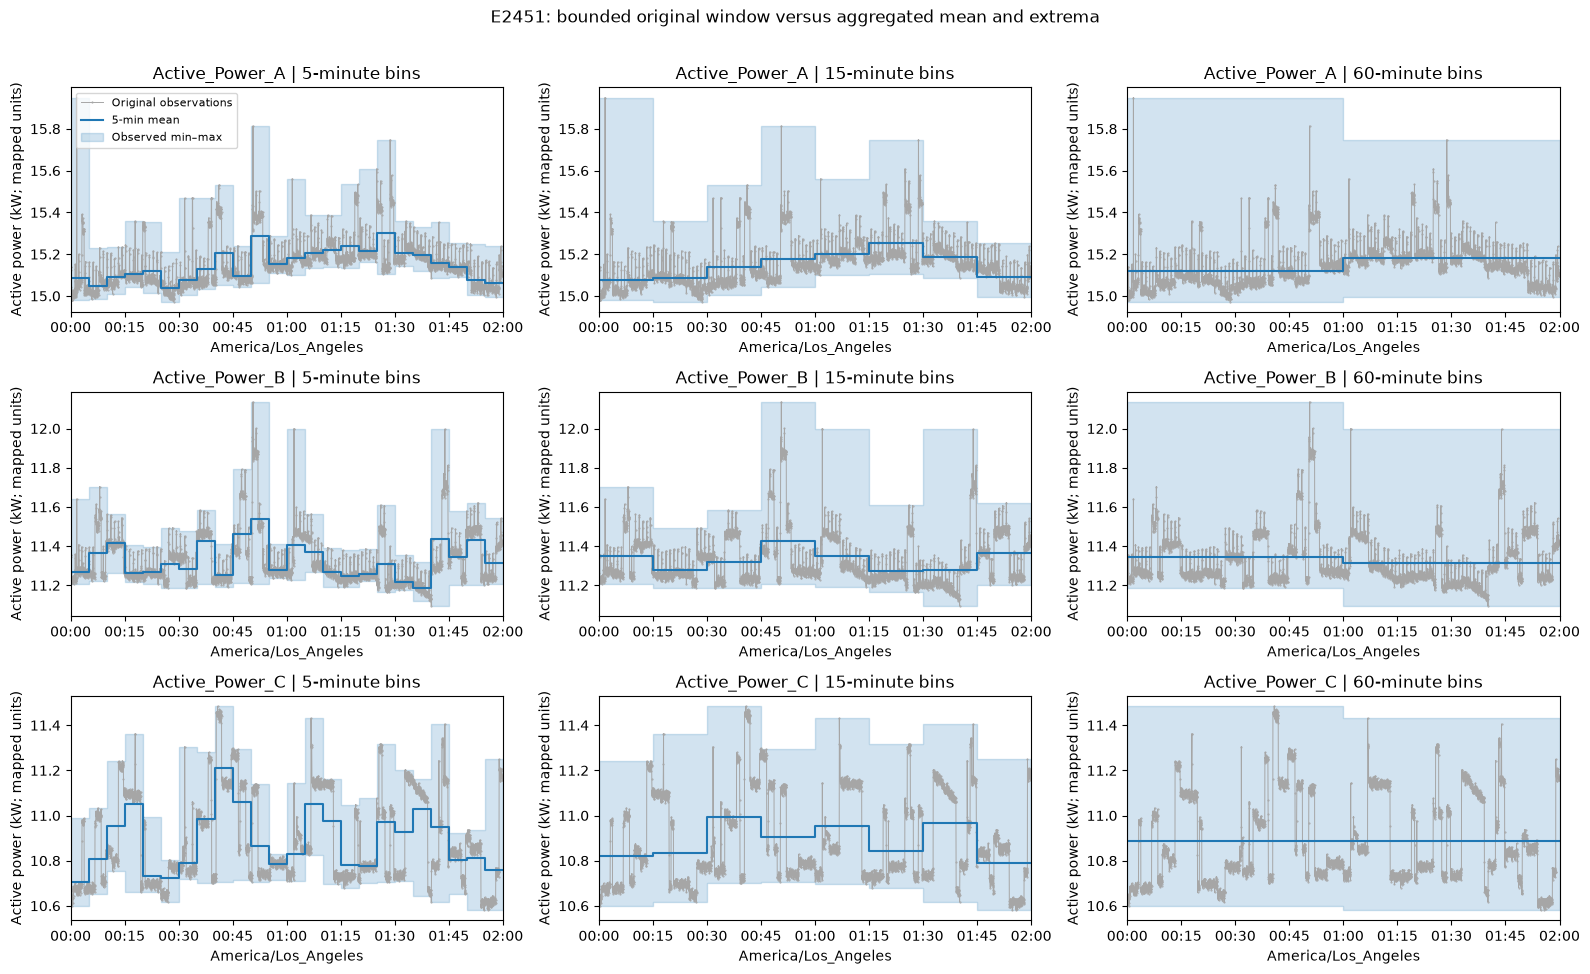

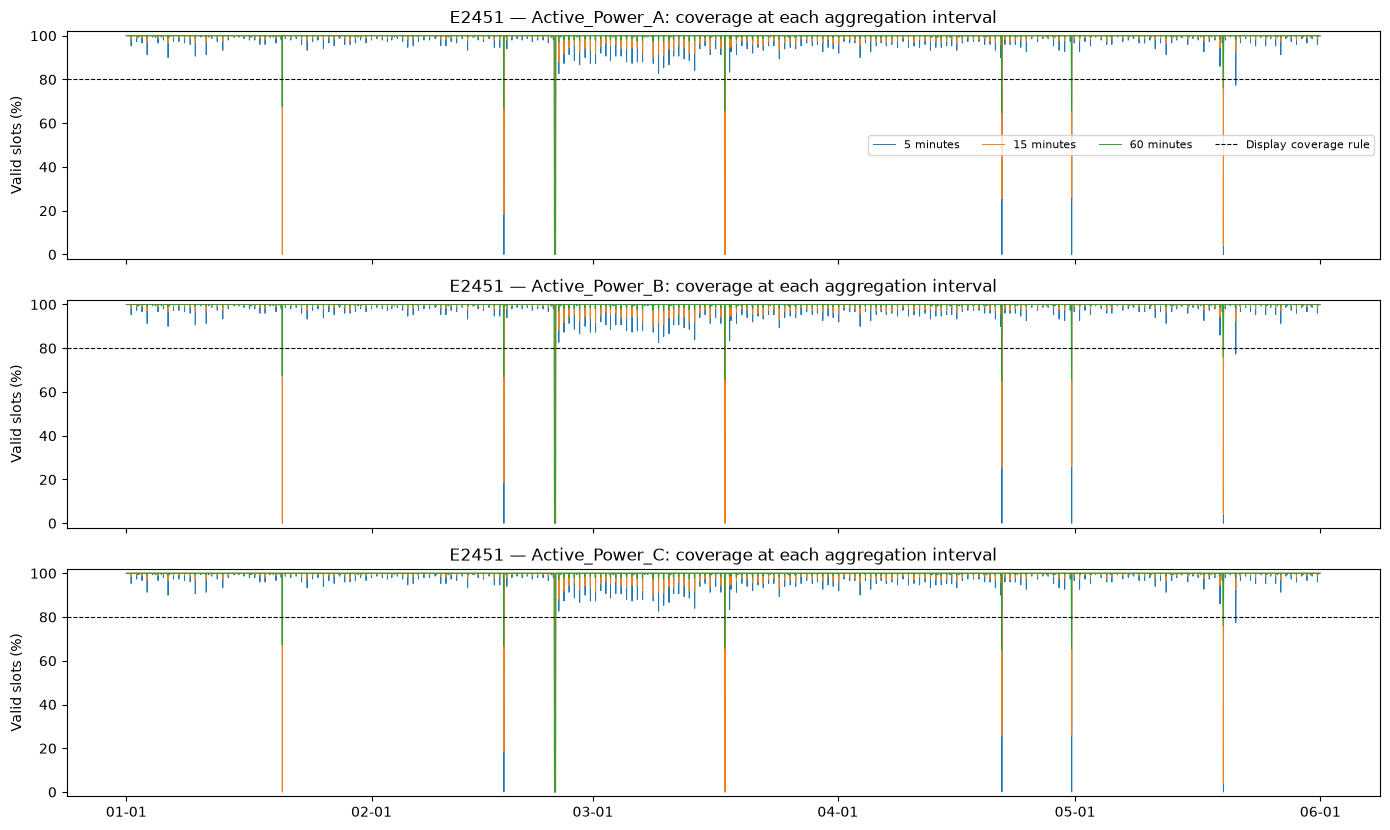

In [19]:
if FULL_RESULT is not None:
    raw = FULL_RESULT['detail']
    meta = FULL_RESULT['metadata']
    if raw.empty:
        print('No accepted measurements in the selected bounded raw window; choose FG_DETAIL_DEVICE/START and rerun F.')
    else:
        fig, axes = plt.subplots(len(FULL_RESULT['channels']), 3, figsize=(16, 3.2*len(FULL_RESULT['channels'])), squeeze=False)
        # Break raw lines at recording gaps rather than connecting across missing periods.
        cuts = np.flatnonzero(np.diff(raw.index.asi8)/1e9 > 1.5*FG_CADENCE_SECONDS) + 1
        segments = np.split(np.arange(len(raw)), cuts)
        for row, channel in enumerate(FULL_RESULT['channels']):
            for col, minutes in enumerate((5, 15, 60)):
                ax = axes[row, col]
                for k, indices in enumerate(segments):
                    ax.plot(raw.index[indices], raw[channel].iloc[indices], color='0.65', linewidth=.7, marker='.', markersize=1,
                            label='Original observations' if k == 0 else None)
                bins = FULL_RESULT['aggregates'][(FG_DETAIL_DEVICE, minutes)]
                window = bins.loc[(bins.index >= meta['detail_start'].floor(f'{minutes}min')) & (bins.index < meta['detail_end'])]
                if len(window):
                    x = window.index.append(pd.DatetimeIndex([window.index[-1]+pd.Timedelta(minutes=minutes)]))
                    mean = window[channel+'__mean_kw'].to_numpy()
                    low = window[channel+'__min_kw'].to_numpy()
                    high = window[channel+'__max_kw'].to_numpy()
                    ax.step(x, np.r_[mean, mean[-1]], where='post', label=f'{minutes}-min mean', color='tab:blue')
                    ax.fill_between(x, np.r_[low, low[-1]], np.r_[high, high[-1]], step='post', alpha=.2, color='tab:blue', label='Observed min–max')
                ax.set_title(f'{channel} | {minutes}-minute bins')
                ax.set_ylabel('Active power (kW; mapped units)')
                ax.set_xlim(meta['detail_start'], meta['detail_end'])
                ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M', tz=ZoneInfo(FG_CALENDAR_TZ)))
                ax.set_xlabel(FG_CALENDAR_TZ)
                if row == 0 and col == 0: ax.legend(fontsize=8)
        fig.suptitle(f'{FG_DETAIL_DEVICE}: bounded original window versus aggregated mean and extrema', y=1.01)
        plt.tight_layout(); plt.show()
        if meta['detail_truncated']:
            print('Raw detail row cap reached; original trace is truncated. Reduce detail duration or review the row cap and rerun F.')

    fig, axes = plt.subplots(len(FULL_RESULT['channels']), 1, figsize=(14, 2.8*len(FULL_RESULT['channels'])), squeeze=False, sharex=True)
    for row, channel in enumerate(FULL_RESULT['channels']):
        ax = axes[row, 0]
        for minutes in (5, 15, 60):
            bins = FULL_RESULT['aggregates'][(FG_DETAIL_DEVICE, minutes)]
            ax.plot(bins.index, bins[channel+'__coverage_pct'], linewidth=.7, label=f'{minutes} minutes')
        ax.axhline(FG_MIN_VALID_COVERAGE*100, color='black', linestyle='--', linewidth=.8, label='Display coverage rule')
        ax.set_ylim(-2, 102); ax.set_ylabel('Valid slots (%)')
        ax.set_title(f'{FG_DETAIL_DEVICE} — {channel}: coverage at each aggregation interval')
        if row == 0: ax.legend(ncol=4, fontsize=8)
    axes[-1, 0].xaxis.set_major_locator(mdates.AutoDateLocator(tz=ZoneInfo(FG_CALENDAR_TZ)))
    axes[-1, 0].xaxis.set_major_formatter(mdates.DateFormatter('%m-%d', tz=ZoneInfo(FG_CALENDAR_TZ)))
    plt.tight_layout(); plt.show()

In [20]:
if AGGREGATION_COMPARISON is not None:
    focus = AGGREGATION_COMPARISON.loc[AGGREGATION_COMPARISON.device.eq(FG_DETAIL_DEVICE)]
    print('Measured peak averaging effects for the selected device (eligible bins only):')
    display(focus[['channel', 'interval_minutes', 'displayed_bins', 'mean_bin_coverage_pct',
                   'max_observed_kw', 'maximum_bin_mean_kw', 'peak_reduction_pct',
                   'median_within_bin_range_kw', 'median_within_bin_std_kw']])
    print('Use the computed values above when describing findings; no full-dataset result is assumed in advance.')
    print('Coverage measures recording/finite-value availability, not whether consumption is normal.')

Measured peak averaging effects for the selected device (eligible bins only):


,channel,interval_minutes,displayed_bins,mean_bin_coverage_pct,max_observed_kw,maximum_bin_mean_kw,peak_reduction_pct,median_within_bin_range_kw,median_within_bin_std_kw
0,Active_Power_A,5,43402,99.796562,69.864422,51.062302,26.912296,0.755381,0.163006
1,Active_Power_B,5,43402,99.796562,65.623492,46.088587,29.768158,0.781694,0.176303
2,Active_Power_C,5,43402,99.796562,63.995566,46.674750,27.065651,0.902043,0.215002
3,Active_Power_A,15,14465,99.796562,69.864422,49.289054,29.450423,3.442332,0.435933
4,Active_Power_B,15,14465,99.796562,65.623492,44.448402,32.267546,2.791533,0.408318
5,Active_Power_C,15,14465,99.796562,63.995566,43.432575,32.131900,2.743766,0.446990
6,Active_Power_A,60,3613,99.796562,69.864422,48.261876,30.920668,12.018883,1.281029
7,Active_Power_B,60,3613,99.796562,65.623492,43.114157,34.300727,12.176521,1.197420
8,Active_Power_C,60,3613,99.796562,63.995566,41.638993,34.934567,12.144539,1.172991


Use the computed values above when describing findings; no full-dataset result is assumed in advance.
Coverage measures recording/finite-value availability, not whether consumption is normal.


### Section G — Temporal Aggregation: Key Findings

We explored how the DERCONNECT electricity measurements can be summarized into **5-minute, 15-minute, and hourly intervals**, rather than using the original two-second readings for every visualization.

The goal was to understand how different time intervals affect the visibility of electricity consumption patterns and determine which resolutions would be most useful for our dashboard.

#### Main Findings

- **5-minute intervals preserve more detail:** Short-term changes in electricity demand remain more visible compared to longer intervals.
- **15-minute intervals provide a balance:** They reduce the number of data points while retaining some short-term fluctuations, making them a useful option for dashboard charts.
- **Hourly intervals simplify long-term trends:** They make overall electricity demand easier to visualize, but averaging can hide sudden spikes or short-duration changes.
- **Minimum and maximum values preserve important information:** Even when average demand appears stable, the observed minimum and maximum measurements can reveal fluctuations that would otherwise be hidden.
- **Data coverage remains important:** Each aggregated interval should include the percentage of available measurements so incomplete periods are not mistaken for normal electricity behavior.
- **Individual electrical phases remain separate:** Measurements from phases A, B, and C were preserved. Total active power was not calculated because the phase aggregation assumptions still require verification.

These observations were supported by a two-hour sample from device E2451. The results illustrate how aggregation affects the measurements, although other devices and periods may behave differently.

#### What Do These Findings Mean?

Temporal aggregation helps make the large DERCONNECT dataset easier to visualize and interpret. However, **using longer time intervals reduces the visibility of short-term electrical changes**.

For example, a sudden increase in electricity demand may be clearly visible in the original two-second measurements but become less noticeable when averaged over an hour.

This means our dashboard should use different time resolutions depending on what the user wants to investigate.

#### Recommended Dashboard Visualizations

| Dashboard Feature | Suggested Resolution | Purpose |
|---|---|---|
| Long-term electricity demand | Hourly | Understand overall consumption trends |
| General demand monitoring | 15 minutes | Observe demand changes without overcrowding charts |
| Detailed demand analysis | 5 minutes | Examine shorter-term fluctuations and peaks |
| Electrical anomaly investigation | Original ~2 seconds | Inspect individual phase measurements and sudden changes |

These are preliminary recommendations that can be adjusted after further analysis.

#### Recommended Next Steps

1. **Evaluate additional time windows:** Compare aggregation results across other devices and periods to determine whether the same patterns hold.
2. **Preserve peak measurements:** Include observed minimum and maximum power alongside averages to avoid hiding important fluctuations.
3. **Track measurement coverage:** Identify incomplete intervals and display missing periods appropriately.
4. **Verify phase aggregation:** Confirm how phases A, B, and C should be combined before calculating total active power.
5. **Proceed with building consumption analysis:** Investigate daily and weekly electricity patterns to better understand typical behavior across the five meters.

#### Dashboard Implications

These findings help determine **how real DERCONNECT measurements should be displayed without losing important electrical information**.

For building managers, hourly and 15-minute measurements can provide a clearer overview of electricity demand and potential unusual consumption.

For electrical engineers, shorter intervals and individual phase measurements can provide more detailed evidence when investigating detected anomalies.

Ultimately, using multiple time resolutions will allow our dashboard to support both **general electricity monitoring and detailed anomaly investigation**, helping users better understand the nature and potential significance of unusual electrical behavior.

*Note: Section G only evaluates aggregation methods. It does not implement anomaly detection, historical baselines, or the final dashboard data pipeline.*